In [ ]:
%matplotlib widget
import matplotlib.pyplot as plt

import sys
import os

sys.path.append('.')

from math import gcd
from functools import reduce

import pickle

import numpy as np
import pandas as pd

from tqdm import tqdm

from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

from anomaly_detection_models import *

torch.set_default_dtype(torch.float64)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

## Config parameters

In [ ]:
data_dir = os.path.join('.', 'data')

# KAN model properties
input_size = 5000
hidden_layers = 3
output_size = 5000
epochs = 5000
learning_rate = 0.001
train_samples = 5000

MODEL_PATH = "lstm_anomaly_model.pth"

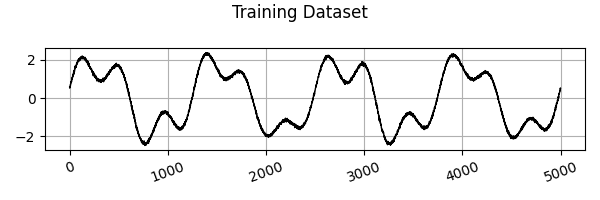

In [ ]:
# Create a LSTM model    
model = LSTMAnomaly()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Load train and test dataset
df_train = pd.read_pickle(os.path.join(data_dir, "train_data.pkl"))
df_test = pd.read_pickle(os.path.join(data_dir, "test_data.pkl"))

# Graph the train dataset
fig, ax = plt.subplots(1, 1, sharex='col', figsize=(6, 2))
fig.suptitle('Training Dataset')
ax.plot(df_train.iloc[1,:], color='black', linewidth=1)
ax.grid(True)

plt.xticks(rotation=20)
fig.tight_layout()

train_tmp = []
test_tmp = []
for col in df_train.columns: 
    train_tmp.append(df_train[col])
    test_tmp.append(df_test[col])
dataset = {}
dataset["train_input"] = torch.transpose(torch.Tensor(train_tmp), 0, 1)
dataset["train_label"] = torch.transpose(torch.Tensor(train_tmp), 0, 1)
dataset["test_input"] = torch.transpose(torch.Tensor(test_tmp), 0, 1)
dataset["test_label"] = torch.transpose(torch.Tensor(test_tmp), 0, 1)

In [ ]:
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    output = model(dataset["train_input"])
    loss = criterion(output.squeeze(), dataset["train_label"])
    loss.backward()
    optimizer.step()
    print(f"Epoch {epoch+1}/{epochs}, Loss: {loss.item():.6f}")


Epoch 1/5000, Loss: 7.681050
Epoch 2/5000, Loss: 7.662503
Epoch 3/5000, Loss: 7.639940
Epoch 4/5000, Loss: 7.626651
Epoch 5/5000, Loss: 7.609687
Epoch 6/5000, Loss: 7.589040
Epoch 7/5000, Loss: 7.564009
Epoch 8/5000, Loss: 7.543763
Epoch 9/5000, Loss: 7.523252
Epoch 10/5000, Loss: 7.501767
Epoch 11/5000, Loss: 7.480477
Epoch 12/5000, Loss: 7.458665
Epoch 13/5000, Loss: 7.436592
Epoch 14/5000, Loss: 7.414713
Epoch 15/5000, Loss: 7.392450
Epoch 16/5000, Loss: 7.370379
Epoch 17/5000, Loss: 7.348210
Epoch 18/5000, Loss: 7.325940
Epoch 19/5000, Loss: 7.303792
Epoch 20/5000, Loss: 7.281565
Epoch 21/5000, Loss: 7.259369
Epoch 22/5000, Loss: 7.237245
Epoch 23/5000, Loss: 7.215090
Epoch 24/5000, Loss: 7.192961
Epoch 25/5000, Loss: 7.170935
Epoch 26/5000, Loss: 7.148877
Epoch 27/5000, Loss: 7.126900
Epoch 28/5000, Loss: 7.104981
Epoch 29/5000, Loss: 7.083085
Epoch 30/5000, Loss: 7.061238
Epoch 31/5000, Loss: 7.039472
Epoch 32/5000, Loss: 7.017740
Epoch 33/5000, Loss: 6.996061
Epoch 34/5000, Loss

In [ ]:
# === After training (continue from previous code) ===
torch.save(model.state_dict(), MODEL_PATH)
print(f"Model saved to {MODEL_PATH}")

Model saved to lstm_anomaly_model.pth
